In [1]:
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

# works whether the notebook runs from notebooks/ or from the repo root
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
FIG = ROOT / 'figures'
FIG.mkdir(exist_ok=True)

COLORS = {'fake': '#d1495b', 'real': '#2e86ab'}
plt.rcParams.update({'figure.dpi': 110,
                     'axes.spines.top': False,
                     'axes.spines.right': False})

LOAD AND OVERVIEW

In [2]:
df = pd.read_csv(ROOT / 'data' / 'headlines_clean.csv')
print('shape:', df.shape)
print('nulls:', int(df.isna().sum().sum()))
display(df.head())
print(df['label'].value_counts())
print(df['label'].value_counts(normalize=True).round(3))

shape: (38705, 3)
nulls: 0


,title,subject,label
0,donald trump sends out embarrassing new year e...,News,fake
1,drunk bragging trump staffer started russian c...,News,fake
2,sheriff david clarke becomes an internet joke ...,News,fake
3,trump is so obsessed he even has obama name co...,News,fake
4,pope francis just called out donald trump duri...,News,fake


label
real    20811
fake    17894
Name: count, dtype: int64
label
real    0.538
fake    0.462
Name: proportion, dtype: float64


CHART 1: HEADLINE LENGTH BY LABEL

In [3]:
df['n_words'] = df['title'].str.split().str.len()
df['n_chars'] = df['title'].str.len()
print(df.groupby('label')[['n_words', 'n_chars']].describe().round(1).T)

label             fake     real
n_words count  17894.0  20811.0
        mean      14.1     10.0
        std        4.1      1.7
        min        1.0      4.0
        25%       11.0      9.0
        50%       13.0     10.0
        75%       16.0     11.0
        max       44.0     20.0
n_chars count  17894.0  20811.0
        mean      83.9     62.8
        std       23.7      9.1
        min        8.0     22.0
        25%       70.0     57.0
        50%       81.0     63.0
        75%       93.0     68.0
        max      266.0    129.0


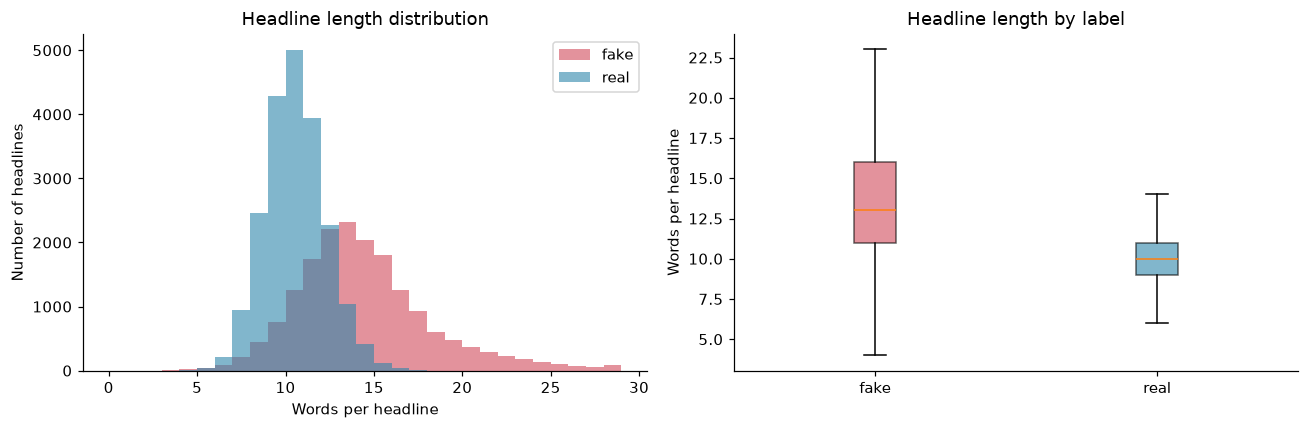

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

bins = np.arange(0, df['n_words'].quantile(0.995) + 2, 1)
for label in ['fake', 'real']:
    axes[0].hist(df.loc[df['label'] == label, 'n_words'], bins=bins,
                 alpha=0.6, label=label, color=COLORS[label])
axes[0].set_xlabel('Words per headline')
axes[0].set_ylabel('Number of headlines')
axes[0].set_title('Headline length distribution')
axes[0].legend()

data = [df.loc[df['label'] == l, 'n_words'] for l in ['fake', 'real']]
bp = axes[1].boxplot(data, patch_artist=True, showfliers=False)
axes[1].set_xticklabels(['fake', 'real'])
for patch, l in zip(bp['boxes'], ['fake', 'real']):
    patch.set_facecolor(COLORS[l])
    patch.set_alpha(0.6)
axes[1].set_ylabel('Words per headline')
axes[1].set_title('Headline length by label')

plt.tight_layout()
plt.savefig(FIG / 'eda_length.png', dpi=150, bbox_inches='tight')
plt.show()

CHART 2: TOP 20 WORDS PER CLASS

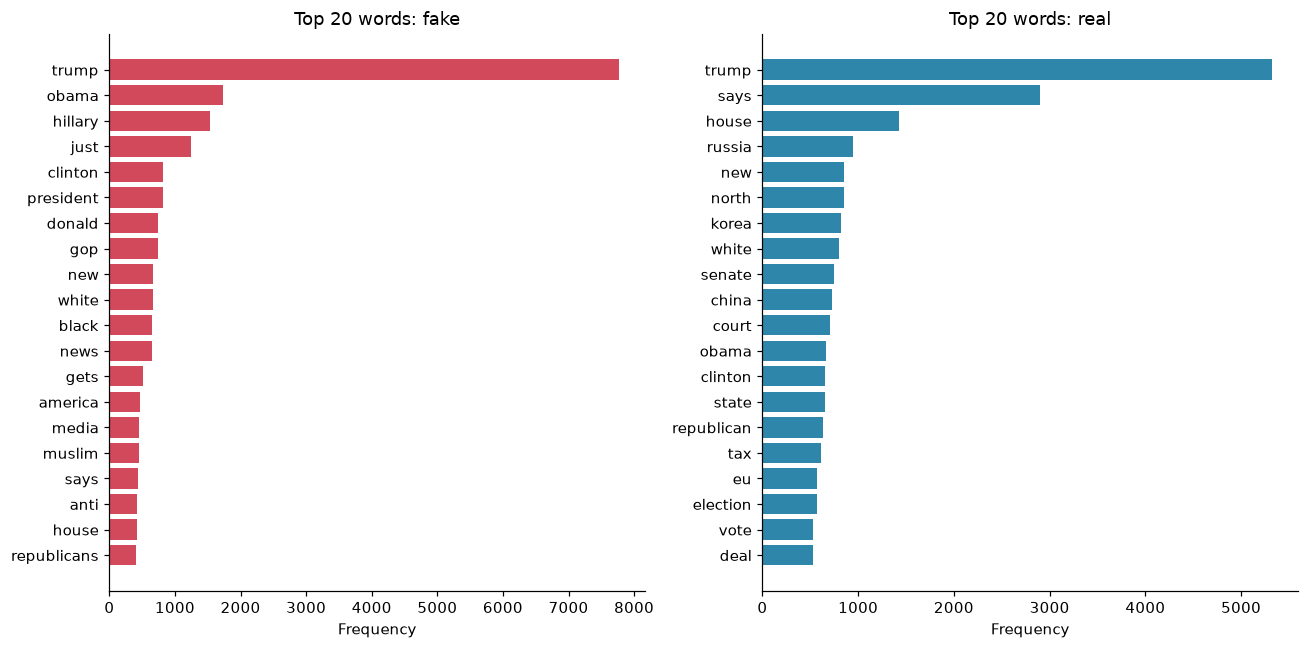

In [5]:
def count_words(titles):
    counts = Counter()
    for t in titles:
        counts.update(w for w in t.split() if w not in ENGLISH_STOP_WORDS and len(w) > 1)
    return counts


fake_counts = count_words(df.loc[df['label'] == 'fake', 'title'])
real_counts = count_words(df.loc[df['label'] == 'real', 'title'])

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
for ax, label, counts in zip(axes, ['fake', 'real'], [fake_counts, real_counts]):
    words, values = zip(*counts.most_common(20))
    ax.barh(words[::-1], values[::-1], color=COLORS[label])
    ax.set_title(f'Top 20 words: {label}')
    ax.set_xlabel('Frequency')

plt.tight_layout()
plt.savefig(FIG / 'eda_top_words.png', dpi=150, bbox_inches='tight')
plt.show()

MOST DISTINCTIVE WORDS

In [6]:
rows = []
for w in set(fake_counts) | set(real_counts):
    f, r = fake_counts[w], real_counts[w]
    if f + r >= 100:
        rows.append((w, f, r, np.log((f + 1) / (r + 1))))

dist = pd.DataFrame(rows, columns=['word', 'fake_count', 'real_count', 'log_ratio'])
dist = dist.sort_values('log_ratio', ascending=False)

print('Lean fake:')
display(dist.head(15).round(2))
print('Lean real:')
display(dist.tail(15).iloc[::-1].round(2))

Lean fake:


,word,fake_count,real_count,log_ratio
375,wow,220,0,5.40
33,hilarious,196,0,5.28
491,busted,132,0,4.89
362,hilariously,126,0,4.84
573,ck,122,0,4.81
182,bombshell,121,0,4.80
158,supporter,225,1,4.73
61,epic,112,0,4.73
420,lol,109,0,4.70
178,dem,108,0,4.69


Lean real:


,word,fake_count,real_count,log_ratio
432,myanmar,0,267,-5.59
316,catalan,0,188,-5.24
284,rohingya,0,178,-5.19
380,kurdish,0,143,-4.97
304,catalonia,0,125,-4.84
252,xi,0,124,-4.83
508,envoy,0,116,-4.76
262,zimbabwe,1,164,-4.41
615,egypt,1,122,-4.12
482,turkish,2,154,-3.94


SUBJECT BY LABEL(LEAKAGE EVIDENCE)

label,fake,real
subject,,
Government News,531,0
News,9049,0
US_News,782,0
left-news,705,0
politics,6827,0
politicsNews,0,11142
worldnews,0,9669


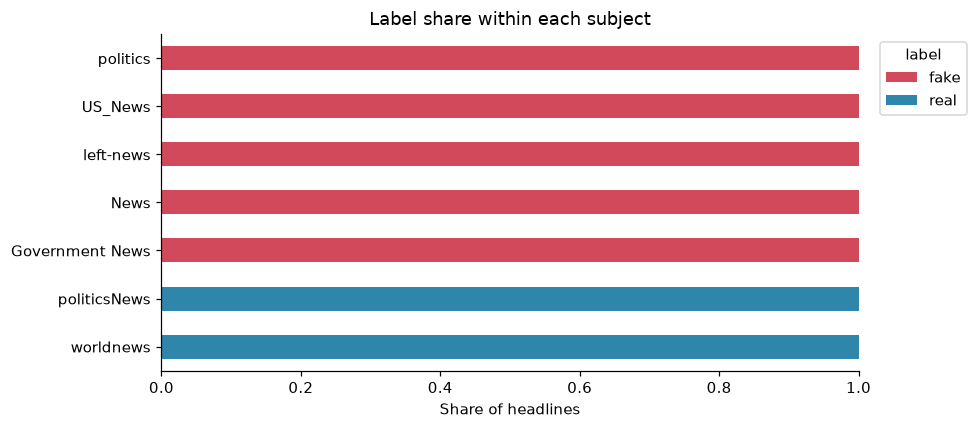

Predicting the label from subject alone: 100.0% accuracy


In [7]:
ct = pd.crosstab(df['subject'], df['label'])
display(ct)

share = ct.div(ct.sum(axis=1), axis=0).sort_values('fake')
ax = share[['fake', 'real']].plot(kind='barh', stacked=True,
                                  color=[COLORS['fake'], COLORS['real']], figsize=(9, 4))
ax.set_xlabel('Share of headlines')
ax.set_ylabel('')
ax.set_title('Label share within each subject')
ax.legend(title='label', bbox_to_anchor=(1.02, 1), loc='upper left')

plt.tight_layout()
plt.savefig(FIG / 'eda_subject.png', dpi=150, bbox_inches='tight')
plt.show()

subject_acc = ct.max(axis=1).sum() / ct.values.sum()
print(f'Predicting the label from subject alone: {subject_acc:.1%} accuracy')

LEAKAGE CHECK (FIRST AND LAST WORDS)

In [8]:
for label in ['fake', 'real']:
    words = df.loc[df['label'] == label, 'title'].str.split()
    print(label, 'first words:', Counter(words.str[0]).most_common(10))
    print(label, 'last words: ', Counter(words.str[-1]).most_common(10))
    print()

fake first words: [('trump', 1680), ('the', 454), ('obama', 348), ('hillary', 279), ('this', 255), ('donald', 232), ('wow', 219), ('fox', 182), ('president', 157), ('cnn', 142)]
fake last words:  [('trump', 572), ('it', 219), ('him', 203), ('president', 116), ('america', 116), ('obama', 113), ('hillary', 111), ('speech', 108), ('election', 98), ('them', 88)]

real first words: [('trump', 2423), ('us', 1617), ('obama', 376), ('china', 333), ('russia', 299), ('white', 289), ('senate', 284), ('house', 265), ('clinton', 239), ('turkey', 229)]
real last words:  [('house', 291), ('trump', 241), ('sources', 237), ('bill', 200), ('official', 200), ('says', 196), ('poll', 171), ('minister', 165), ('deal', 157), ('vote', 151)]

